# News Topic Classification - Data Exploration

Exploring the AG News dataset before building the PyTorch model.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re
from collections import Counter

# Load the dataset
train_df = pd.read_csv('../data/train.csv', header=None, names=['label', 'title', 'description'])
test_df = pd.read_csv('../data/test.csv', header=None, names=['label', 'title', 'description'])

class_names = ['World', 'Sports', 'Business', 'Sci/Tech']
train_df['label'] = train_df['label'] - 1  # 0-indexed
train_df['class_name'] = train_df['label'].map(lambda x: class_names[x])
train_df['text'] = train_df['title'] + ' ' + train_df['description']

print(f"Training set size: {len(train_df)}")
print(f"Test set size: {len(test_df)}")

/usr/lib/python3/dist-packages/pyparsing/core.py:5640: SyntaxWarning: 'return' in a 'finally' block
  return self.__class__.__name__ + ": " + retString


Training set size: 120000
Test set size: 7600


In [2]:
train_df[['class_name', 'title', 'description']].head()

,class_name,title,description
0,Business,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,Business,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,Business,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,Business,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,Business,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."


## Class Distribution
Checking if the dataset is balanced across the 4 categories.

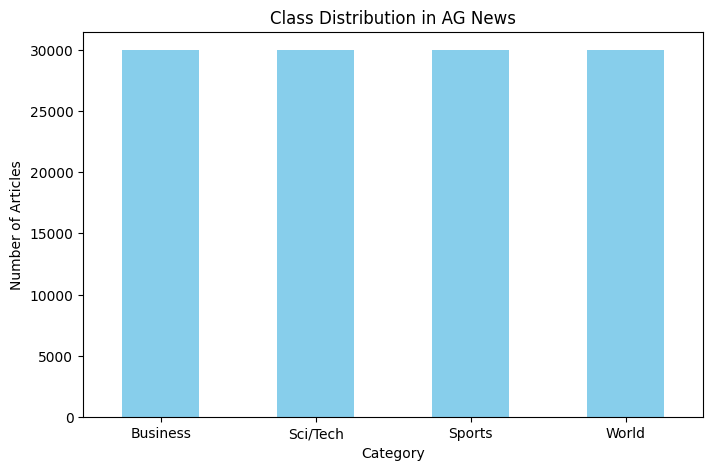

In [3]:
plt.figure(figsize=(8, 5))
train_df['class_name'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Class Distribution in AG News')
plt.xlabel('Category')
plt.ylabel('Number of Articles')
plt.xticks(rotation=0)
plt.show()

The classes are perfectly balanced (30,000 samples each), so we don't need to worry about class weights or oversampling techniques.

## Text Length Analysis
How long are these news snippets? This will help us choose a `MAX_LEN` for padding/truncating our sequences.

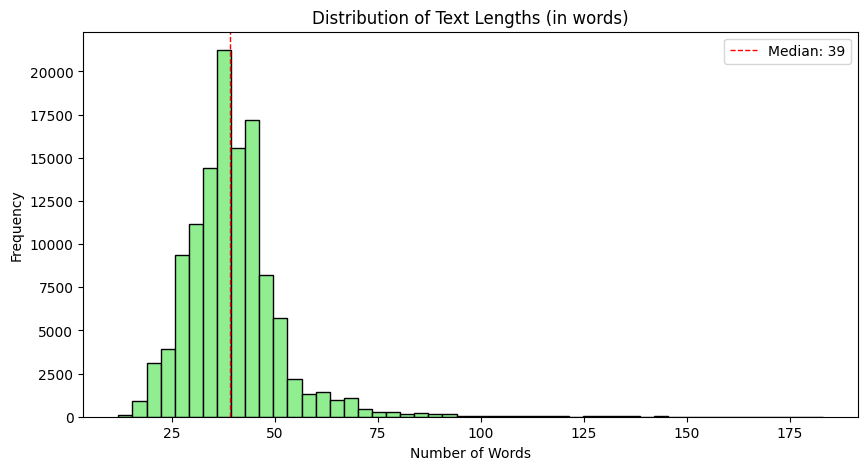

Max length: 183
95th percentile length: 58


In [4]:
def tokenize(text):
    return re.findall(r'\b\w+\b', text.lower())

train_df['text_len'] = train_df['text'].apply(lambda x: len(tokenize(x)))

plt.figure(figsize=(10, 5))
plt.hist(train_df['text_len'], bins=50, color='lightgreen', edgecolor='black')
plt.title('Distribution of Text Lengths (in words)')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.axvline(train_df['text_len'].median(), color='red', linestyle='dashed', linewidth=1, label=f"Median: {train_df['text_len'].median():.0f}")
plt.legend()
plt.show()

print(f"Max length: {train_df['text_len'].max()}")
print(f"95th percentile length: {train_df['text_len'].quantile(0.95):.0f}")

Most texts are around 30-45 words long. The 95th percentile is around 63 words. 
A `MAX_LEN` of 50-60 seems like a reasonable choice for our model to balance information retention and computational efficiency.

## Quick Vocabulary Check
Let's see the most common words in each category.

In [5]:
for category in class_names:
    texts = train_df[train_df['class_name'] == category]['text']
    counter = Counter()
    for text in texts:
        counter.update(tokenize(text))
        
    # filter out some very basic stop words for a better view
    stop_words = {'the', 'a', 'to', 'of', 'and', 'in', 's', 'on', 'for', 'that', 'with', 'is', 'at', 'by', 'it', 'as', 'from'}
    common = [(w, c) for w, c in counter.most_common(20) if w not in stop_words][:10]
    
    print(f"\nTop 10 words in {category}:")
    for word, count in common:
        print(f"  {word}: {count}")


Top 10 words in World:
  39: 8923
  said: 7745
  iraq: 5837
  ap: 5787
  an: 5678
  reuters: 5423



Top 10 words in Sports:
  39: 14826
  his: 7851
  ap: 6262
  was: 5327
  he: 4736
  after: 4558



Top 10 words in Business:
  39: 11743
  its: 9567
  reuters: 8717
  said: 7311
  new: 6632
  oil: 6386
  us: 6101



Top 10 words in Sci/Tech:
  39: 9014
  its: 7857
  new: 7153
  has: 6123
  microsoft: 5145
